# Track 1 — Final Consolidation (complete)

**Experiment Plan:** Q1.10, Table 1-A, Figure 1-G, Significance Testing.

This notebook evaluates both CE and Brier base loss experiments over 30 seeds, three capacities, and four values of $\lambda$. It reports the final-epoch metrics, produces the multi-seed box plots, and compares $\lambda=0.1$ with the predictive-only baseline and paired significance tests. It also evaluates the mean and across-seed variance of $\mathrm{MSE}_\eta$ across the tested $\lambda$ values.

## 0. Setup

In [1]:
%%writefile track1_core.py
'''Track 1 core utilities: data-generating process + Legendre basis model.
Copied from Notebook 1 (Setup) so this notebook is self-contained.'''
import numpy as np

TEST_SEED = 999
N_TEST = 50_000
CAPACITY_GRID = [5, 10, 100, 120, 200, 300, 1000]
PRIMARY_CAPACITIES = [10, 100, 1000]
INIT_SCALE = np.sqrt(0.01)


def true_eta(x):
    x = np.asarray(x, dtype=np.float64)
    return 0.1 + 0.8 / (1.0 + np.exp(-4.0 * np.sin(np.pi * x)))

def generate_data(n, seed):
    rng = np.random.default_rng(seed)
    X = rng.uniform(-1.0, 1.0, size=n)
    Y = rng.binomial(1, true_eta(X)).astype(np.float64)
    return X, Y

def get_fixed_test_set():
    return generate_data(n=N_TEST, seed=TEST_SEED)

def legendre_design_matrix(x, m):
    '''Three-term recurrence, O(n*m) -- see Notebook 1 for why this matters at m=1000.'''
    x = np.asarray(x, dtype=np.float64)
    n = x.shape[0]
    Phi = np.empty((n, m + 1), dtype=np.float64)
    Phi[:, 0] = 1.0
    if m >= 1:
        Phi[:, 1] = x
    for k in range(2, m + 1):
        Phi[:, k] = ((2 * k - 1) * x * Phi[:, k - 1] - (k - 1) * Phi[:, k - 2]) / k
    return Phi

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))

def init_theta(m, seed):
    rng = np.random.default_rng(seed)
    return rng.normal(loc=0.0, scale=INIT_SCALE, size=m + 1)

def model_predict(theta, Phi):
    return sigmoid(Phi @ theta)

Writing track1_core.py


In [2]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import pandas as pd
from scipy.stats import wilcoxon
import track1_core as t1

torch.set_default_dtype(torch.float64)

PALETTE_CAPACITY = {10: "#264653", 100: "#2a9d8f", 1000: "#e76f51"}
plt.rcParams.update({
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
    # "font.family": "serif",
    # "font.serif": ["Computer Modern Roman", "CMU Serif"],
    # "mathtext.fontset": "cm",
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 13,
    "figure.titlesize": 14,
    "figure.titleweight": "bold",
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    # "savefig.bbox": "tight",
    # "savefig.pad_inches": 0.05,
    "savefig.format": "pdf"
})

EPOCHS = 1200
N_SEEDS = 30
SEED_LIST = list(range(1, N_SEEDS + 1))
BASE_LOSSES = ["ce", "brier"]
LAMBDA_GRID = [0.0, 0.1, 0.5, 1.0]
BEST_LAMBDA = 0.1

## 1. New metrics: MCE, RMSCE, KSCE

$$\text{MCE} = \max_b |\text{acc}(b)-\text{conf}(b)|, \qquad
\text{RMSCE} = \sqrt{\sum_b \tfrac{n_b}{N}(\text{acc}(b)-\text{conf}(b))^2}$$

Both reuse the same top-label confidence/accuracy binning as ECE (Notebook 3) — MCE is the
worst-bin gap instead of the weighted-mean gap, RMSCE is the $\ell_2$-weighted version.

**KSCE** (Gupta et al. 2020, cited as [4] in the report): a binning-free calibration error based on
the Kolmogorov–Smirnov statistic. Sort predictions ascending, form the cumulative sum of
(label $-$ prediction) in that order, and take the maximum absolute value, normalized by $n$ —
the empirical estimator matching $\sup_z |\int_0^z P(Y{=}1\mid \hat p\le z')\,dP_{\hat p}(z')|$.


In [3]:
def top_label_bins(p, y, B=10):
    p = np.asarray(p, dtype=np.float64); y = np.asarray(y, dtype=np.float64)
    n = len(p)
    conf = np.maximum(p, 1 - p)
    correct = ((p >= 0.5).astype(np.float64) == y).astype(np.float64)
    edges = np.linspace(0.5, 1.0, B + 1)
    bin_idx = np.clip(np.digitize(conf, edges[1:-1], right=False), 0, B - 1)
    bin_conf, bin_acc, bin_count = [], [], []
    for b in range(B):
        mask = bin_idx == b
        nb = mask.sum()
        if nb == 0:
            continue
        bin_conf.append(conf[mask].mean())
        bin_acc.append(correct[mask].mean())
        bin_count.append(nb)
    return np.array(bin_conf), np.array(bin_acc), np.array(bin_count), n


def ece_mce_rmsce(p, y, B=10):
    bc, ba, bcount, n = top_label_bins(p, y, B)
    gaps = np.abs(ba - bc)
    ece = np.sum((bcount / n) * gaps)
    mce = np.max(gaps)
    rmsce = np.sqrt(np.sum((bcount / n) * gaps ** 2))
    return ece, mce, rmsce


def ksce(p, y):
    p = np.asarray(p, dtype=np.float64); y = np.asarray(y, dtype=np.float64)
    order = np.argsort(p)
    p_sorted, y_sorted = p[order], y[order]
    cumsum = np.cumsum(y_sorted - p_sorted)
    return np.max(np.abs(cumsum)) / len(p)

### Sanity checks

In [4]:
rng = np.random.default_rng(0)
n = 200_000

p_cal = rng.uniform(0.05, 0.95, n)
y_cal = rng.binomial(1, p_cal)
ece_c, mce_c, rmsce_c = ece_mce_rmsce(p_cal, y_cal)
ksce_c = ksce(p_cal, y_cal)
print(f"calibrated:    ECE={ece_c:.5f} MCE={mce_c:.5f} RMSCE={rmsce_c:.5f} KSCE={ksce_c:.5f}")
assert ece_c < 0.01 and mce_c < 0.05 and rmsce_c < 0.02 and ksce_c < 0.01

p_over = rng.uniform(0.05, 0.95, n)
y_over = rng.binomial(1, p_over)
p_over_rep = np.clip(0.5 + 1.8 * (p_over - 0.5), 0.01, 0.99)
ece_o, mce_o, rmsce_o = ece_mce_rmsce(p_over_rep, y_over)
ksce_o = ksce(p_over_rep, y_over)
print(f"overconfident: ECE={ece_o:.5f} MCE={mce_o:.5f} RMSCE={rmsce_o:.5f} KSCE={ksce_o:.5f}")
assert ece_o > ece_c and mce_o > mce_c and rmsce_o > rmsce_c and ksce_o > ksce_c
assert mce_c >= ece_c and mce_o >= ece_o  # MCE is a max over the same gaps ECE averages
print("\nOK: all four metrics respond correctly to miscalibration; MCE >= ECE always, as it must.")

calibrated:    ECE=0.00318 MCE=0.00613 RMSCE=0.00382 KSCE=0.00195
overconfident: ECE=0.11829 MCE=0.19225 RMSCE=0.12726 KSCE=0.05872

OK: all four metrics respond correctly to miscalibration; MCE >= ECE always, as it must.


## 2. Training loop and full metric evaluation (Brier calibration/refinement reused from Notebook 2)

In [7]:
def soft_ece_penalty(p, y, B=15, h=0.08):
    n = p.shape[0]
    centers = (torch.arange(1, B + 1, dtype=p.dtype) - 0.5) / B
    w = torch.softmax(-(p.unsqueeze(1) - centers.unsqueeze(0)) ** 2 / (2 * h ** 2), dim=1)
    w_sg = w.detach()
    bin_mass = w_sg.sum(dim=0)
    eps = 1e-12
    pbar = (w_sg * p.unsqueeze(1)).sum(dim=0) / (bin_mass + eps)
    ybar = (w_sg * y.unsqueeze(1)).sum(dim=0) / (bin_mass + eps)
    return ((bin_mass / n) * (ybar - pbar) ** 2).sum()

def ce_loss(p, y):
    eps = 1e-12
    p_c = p.clamp(eps, 1 - eps)
    return -(y * torch.log(p_c) + (1 - y) * torch.log(1 - p_c)).mean()

def brier_loss(p, y):
    return ((p - y) ** 2).mean()

def base_loss_fn(p, y, kind):
    if kind == "ce":
        return ce_loss(p, y)
    if kind == "brier":
        return brier_loss(p, y)
    raise ValueError(f"Unknown base loss: {kind}")

def train_end_to_end(X_tr, Y_tr, m, init_seed, lam, base_loss="ce", lr=0.5, epochs=EPOCHS):
    Phi_tr = torch.tensor(t1.legendre_design_matrix(X_tr, m))
    y_tr_t = torch.tensor(Y_tr)
    theta = torch.tensor(t1.init_theta(m, init_seed), requires_grad=True)
    for step in range(epochs):
        p_tr = torch.sigmoid(Phi_tr @ theta)
        loss = (1 - lam) * soft_ece_penalty(p_tr, y_tr_t) + lam * base_loss_fn(p_tr, y_tr_t, base_loss)
        if theta.grad is not None:
            theta.grad.zero_()
        loss.backward()
        with torch.no_grad():
            theta -= lr * theta.grad
    return theta.detach().numpy()

def brier_cal_ref(p, y, B=10, eps=1e-12):
    '''Reused from Notebook 2: Brier calibration-refinement decomposition, Total = Cal + Ref exactly.'''
    p = np.clip(np.asarray(p, dtype=np.float64), eps, 1 - eps)
    y = np.asarray(y, dtype=np.float64)
    n = len(p)
    edges = np.linspace(0.0, 1.0, B + 1)
    bin_idx = np.clip(np.digitize(p, edges[1:-1], right=False), 0, B - 1)
    brier_total = np.mean((p - y) ** 2)
    brier_cal = 0.0
    for b in range(B):
        mask = bin_idx == b
        n_b = mask.sum()
        if n_b == 0:
            continue
        pbar_b, ybar_b = p[mask].mean(), y[mask].mean()
        brier_cal += (n_b / n) * (pbar_b - ybar_b) ** 2
    return brier_cal, brier_total - brier_cal

def eval_all_metrics(p_te, Y_te, eta_te):
    p_te_c = np.clip(p_te, 1e-12, 1 - 1e-12)
    test_ce = np.mean(-Y_te * np.log(p_te_c) - (1 - Y_te) * np.log(1 - p_te_c))
    brier = np.mean((p_te - Y_te) ** 2)
    mse_eta = np.mean((p_te - eta_te) ** 2)
    ece, mce, rmsce = ece_mce_rmsce(p_te, Y_te, B=10)
    ks = ksce(p_te, Y_te)
    cal, ref = brier_cal_ref(p_te, Y_te, B=10)
    return {"test_ce": test_ce, "brier": brier, "ece": ece, "mse_eta": mse_eta,
            "brier_cal": cal, "brier_ref": ref, "mce": mce, "rmsce": rmsce, "ksce": ks}

### Sanity check — Total = Cal + Ref still holds exactly on a fresh model

In [8]:
X_te, Y_te = t1.get_fixed_test_set()
eta_te = t1.true_eta(X_te)

theta_check = train_end_to_end(*t1.generate_data(100, seed=1), m=100, init_seed=10042, lam=0.5, base_loss="ce")
Phi_te_check = t1.legendre_design_matrix(X_te, 100)
p_te_check = t1.model_predict(theta_check, Phi_te_check)
metrics_check = eval_all_metrics(p_te_check, Y_te, eta_te)
print(metrics_check)
assert abs(metrics_check["brier"] - (metrics_check["brier_cal"] + metrics_check["brier_ref"])) < 1e-9

theta_check_brier = train_end_to_end(*t1.generate_data(100, seed=1), m=100, init_seed=10042, lam=0.5, base_loss="brier")
p_te_check_brier = t1.model_predict(theta_check_brier, Phi_te_check)
metrics_check_brier = eval_all_metrics(p_te_check_brier, Y_te, eta_te)
print(metrics_check_brier)
assert abs(metrics_check_brier["brier"] - (metrics_check_brier["brier_cal"] + metrics_check_brier["brier_ref"])) < 1e-9
print("\nOK: CE and Brier objectives train; Total = Calibration + Refinement holds for both.")

{'test_ce': np.float64(0.5854648820627176), 'brier': np.float64(0.17137132760204404), 'ece': np.float64(0.09966480944194026), 'mse_eta': np.float64(0.023306753778268144), 'brier_cal': np.float64(0.01302389076505905), 'brier_ref': np.float64(0.158347436836985), 'mce': np.float64(0.13952432443037777), 'rmsce': np.float64(0.1102912991052636), 'ksce': np.float64(0.06102839479183553)}
{'test_ce': np.float64(0.5122721189187697), 'brier': np.float64(0.16106527123897565), 'ece': np.float64(0.06771268054508589), 'mse_eta': np.float64(0.013156298166772542), 'brier_cal': np.float64(0.005616162971290858), 'brier_ref': np.float64(0.1554491082676848), 'mce': np.float64(0.15265212877268486), 'rmsce': np.float64(0.07423978307421819), 'ksce': np.float64(0.04976197154858913)}

OK: CE and Brier objectives train; Total = Calibration + Refinement holds for both.


## 3. The 30-seed sweep: 3 capacities × 4 $\lambda$ × 30 seeds × 2 base losses (720 runs)

Both CE and Brier use the same objective form, $\mathcal{L}=(1-\lambda)\mathcal{L}_{\mathrm{ECE}}+\lambda\mathcal{L}_{\mathrm{base}}$. At $\lambda=1$, each run is its corresponding predictive-only baseline. The same data and initialization seeds are paired across base losses.

In [11]:
import time

t_start = time.time()
records = []
for seed in SEED_LIST:
    X_tr, Y_tr = t1.generate_data(n=100, seed=seed)
    for base_loss in BASE_LOSSES:
        for m in t1.PRIMARY_CAPACITIES:
            Phi_te_m = t1.legendre_design_matrix(X_te, m)
            for lam in LAMBDA_GRID:
                theta = train_end_to_end(X_tr, Y_tr, m, init_seed=10000 + seed, lam=lam, base_loss=base_loss)
                p_te = t1.model_predict(theta, Phi_te_m)
                records.append({"seed": seed, "base_loss": base_loss, "m": m, "lam": lam,
                                **eval_all_metrics(p_te, Y_te, eta_te)})
    if seed % 5 == 0:
        print(f"seed {seed}/{N_SEEDS} done ({time.time() - t_start:.0f}s elapsed)")

n_runs = N_SEEDS * len(BASE_LOSSES) * len(t1.PRIMARY_CAPACITIES) * len(LAMBDA_GRID)
print(f"\nFull sweep ({n_runs} runs) completed in {time.time() - t_start:.0f}s")
sweep_df_06 = pd.DataFrame(records)
sweep_df = sweep_df_06

sweep_df_06.to_csv("sweep_df_06.csv", index=False)
sweep_df_06.to_excel("sweep_df_06.xlsx", index=False)
display(sweep_df_06)

seed 5/30 done (77s elapsed)
seed 10/30 done (155s elapsed)
seed 15/30 done (232s elapsed)
seed 20/30 done (308s elapsed)
seed 25/30 done (384s elapsed)
seed 30/30 done (459s elapsed)

Full sweep (720 runs) completed in 459s


,seed,base_loss,m,lam,test_ce,brier,ece,mse_eta,brier_cal,brier_ref,mce,rmsce,ksce
0,1,ce,10,0.0,0.695796,0.251324,0.065079,0.104729,0.004529,0.246795,0.065079,0.065079,0.037563
1,1,ce,10,0.1,0.508572,0.157850,0.061002,0.010104,0.004396,0.153454,0.109265,0.068290,0.041655
2,1,ce,10,0.5,0.536682,0.160141,0.065125,0.012618,0.005887,0.154254,0.141672,0.078359,0.048473
3,1,ce,10,1.0,0.563415,0.161226,0.071004,0.013785,0.007057,0.154168,0.154225,0.087962,0.052701
4,1,ce,100,0.0,0.695516,0.251177,0.030059,0.104574,0.000934,0.250243,0.723578,0.049427,0.019709
...,...,...,...,...,...,...,...,...,...,...,...,...,...
715,30,brier,100,1.0,0.569323,0.188276,0.048034,0.040207,0.005235,0.183040,0.151904,0.066225,0.019116
716,30,brier,1000,0.0,0.694010,0.250413,0.020488,0.103742,0.000590,0.249823,0.271445,0.030212,0.019488
717,30,brier,1000,0.1,0.499249,0.159169,0.057380,0.011233,0.004381,0.154788,0.956975,0.065655,0.029023
718,30,brier,1000,0.5,0.534020,0.173784,0.044640,0.025658,0.007196,0.166588,0.351778,0.060764,0.028249


## 4. Table 1-A — Final-epoch metrics (mean ± std over 30 seeds)

Table 1-A includes a base-loss index level so CE and Brier results can be compared in the same table. The SD is computed across the 30 paired seed runs within each (base loss, capacity, $\lambda$) configuration.

In [12]:
agg_cols = ["test_ce", "brier", "ece", "mse_eta", "brier_cal", "brier_ref", "mce", "rmsce", "ksce"]
summary = sweep_df_06.groupby(["base_loss", "m", "lam"])[agg_cols].agg(["mean", "std"]).reset_index()

table_1a = pd.DataFrame({"base_loss": summary["base_loss"], "m": summary["m"], "lam": summary["lam"]})
col_labels = {"test_ce": "Test CE", "brier": "Brier", "ece": "ECE", "mse_eta": "MSEeta",
              "brier_cal": "Cal(Brier)", "brier_ref": "Ref(Brier)", "mce": "MCE",
              "rmsce": "RMSCE", "ksce": "KSCE"}
for col in agg_cols:
    table_1a[col_labels[col]] = (summary[(col, "mean")].round(4).astype(str) + " ± " +
                                   summary[(col, "std")].round(4).astype(str))
table_1a = table_1a.set_index(["base_loss", "m", "lam"])

table_1a.to_csv("Table_1a.csv")
table_1a.to_excel("Table_1a.xlsx")
display(table_1a)

Test CE            Brier              ECE  \
base_loss m    lam                                                      
brier     10   0.0  0.5969 ± 0.0905  0.2032 ± 0.0436  0.0528 ± 0.0269   
               0.1  0.4981 ± 0.0179  0.1581 ± 0.0053  0.0446 ± 0.0196   
               0.5   0.501 ± 0.0174  0.1589 ± 0.0057  0.0478 ± 0.0165   
               1.0  0.5098 ± 0.0193   0.1612 ± 0.006  0.0541 ± 0.0163   
          100  0.0  0.6233 ± 0.0938   0.2163 ± 0.045  0.0497 ± 0.0177   
               0.1  0.5008 ± 0.0173   0.159 ± 0.0053  0.0484 ± 0.0201   
               0.5   0.518 ± 0.0159  0.1662 ± 0.0064  0.0515 ± 0.0174   
               1.0  0.5458 ± 0.0219  0.1776 ± 0.0098  0.0592 ± 0.0157   
          1000 0.0  0.6001 ± 0.0939  0.2054 ± 0.0449  0.0506 ± 0.0302   
               0.1  0.5019 ± 0.0163  0.1593 ± 0.0051  0.0475 ± 0.0195   
               0.5  0.5158 ± 0.0156  0.1654 ± 0.0061  0.0429 ± 0.0171   
               1.0   0.534 ± 0.0187  0.1733 ± 0.0081  0.0442 ± 0.0174   
ce        10   0.0  0.5969 ± 0.0905  0.2032 ± 0.0436  0.0528 ± 0.0269   
               0.1   0.4981 ± 0.017  0.1577 ± 0.0054  0.0459 ± 0.0179   
               0.5  0.5293 ± 0.0292  0.1637 ± 0.0071   0.063 ± 0.0184   
               1.0  0.5512 ± 0.0424  0.1663 ± 0.0077  0.0694 ± 0.0195   
          100  0.0  0.6233 ± 0.0938   0.2163 ± 0.045  0.0497 ± 0.0177   
               0.1  0.5077 ± 0.0181  0.1604 ± 0.0055  0.0545 ± 0.0212   
               0.5  0.5841 ± 0.0268  0.1805 ± 0.0088  0.0917 ± 0.0175   
               1.0  0.6573 ± 0.0363  0.1958 ± 0.0125  0.1217 ± 0.0178   
          1000 0.0  0.6001 ± 0.0939  0.2054 ± 0.0449  0.0506 ± 0.0302   
               0.1  0.5099 ± 0.0176  0.1607 ± 0.0053  0.0546 ± 0.0202   
               0.5  0.5724 ± 0.0274  0.1766 ± 0.0074  0.0854 ± 0.0212   
               1.0  0.6252 ± 0.0368  0.1855 ± 0.0082  0.1143 ± 0.0184   

                             MSEeta       Cal(Brier)       Ref(Brier)  \
base_loss m    lam                                                      
brier     10   0.0  0.0559 ± 0.0443   0.006 ± 0.0052  0.1973 ± 0.0447   
               0.1  0.0103 ± 0.0053  0.0052 ± 0.0038   0.153 ± 0.0028   
               0.5  0.0114 ± 0.0057  0.0053 ± 0.0038  0.1536 ± 0.0032   
               1.0  0.0138 ± 0.0061  0.0059 ± 0.0034  0.1553 ± 0.0042   
          100  0.0  0.0692 ± 0.0458  0.0048 ± 0.0041  0.2115 ± 0.0471   
               0.1  0.0112 ± 0.0053  0.0057 ± 0.0042  0.1534 ± 0.0018   
               0.5  0.0186 ± 0.0065   0.006 ± 0.0037  0.1601 ± 0.0049   
               1.0    0.0302 ± 0.01  0.0066 ± 0.0037   0.171 ± 0.0089   
          1000 0.0   0.058 ± 0.0456   0.0058 ± 0.007  0.1995 ± 0.0468   
               0.1   0.0114 ± 0.005  0.0055 ± 0.0041  0.1538 ± 0.0016   
               0.5  0.0178 ± 0.0062  0.0047 ± 0.0032  0.1607 ± 0.0049   
               1.0  0.0258 ± 0.0082  0.0046 ± 0.0031  0.1688 ± 0.0077   
ce        10   0.0  0.0559 ± 0.0443   0.006 ± 0.0052  0.1973 ± 0.0447   
               0.1  0.0101 ± 0.0054  0.0051 ± 0.0038  0.1525 ± 0.0029   
               0.5  0.0163 ± 0.0072  0.0075 ± 0.0036   0.1562 ± 0.005   
               1.0  0.0189 ± 0.0078   0.009 ± 0.0039  0.1573 ± 0.0053   
          100  0.0  0.0692 ± 0.0458  0.0048 ± 0.0041  0.2115 ± 0.0471   
               0.1  0.0127 ± 0.0054   0.006 ± 0.0042  0.1545 ± 0.0026   
               0.5    0.033 ± 0.009  0.0123 ± 0.0046  0.1682 ± 0.0072   
               1.0  0.0482 ± 0.0128   0.019 ± 0.0054  0.1768 ± 0.0103   
          1000 0.0   0.058 ± 0.0456   0.0058 ± 0.007  0.1995 ± 0.0468   
               0.1  0.0129 ± 0.0052  0.0061 ± 0.0042  0.1546 ± 0.0026   
               0.5  0.0289 ± 0.0075  0.0105 ± 0.0047  0.1661 ± 0.0069   
               1.0  0.0378 ± 0.0083  0.0162 ± 0.0048  0.1694 ± 0.0076   

                                MCE            RMSCE             KSCE  
base_loss m    lam                                                     
brier     10   0.0  0.1628 ± 0.1489  0.0621 ± 0.0307  0.0478 ± 0.0236  
              

## 5. Figure 1-G — Multi-seed box plots

Figure 1-G compares CE and Brier base losses while preserving the four metric panels and capacity color coding. Rows distinguish base loss; columns show Test CE, Brier, MSE η , and ECE. Each box summarizes 30 seeds for a capacity/ λ  combination.


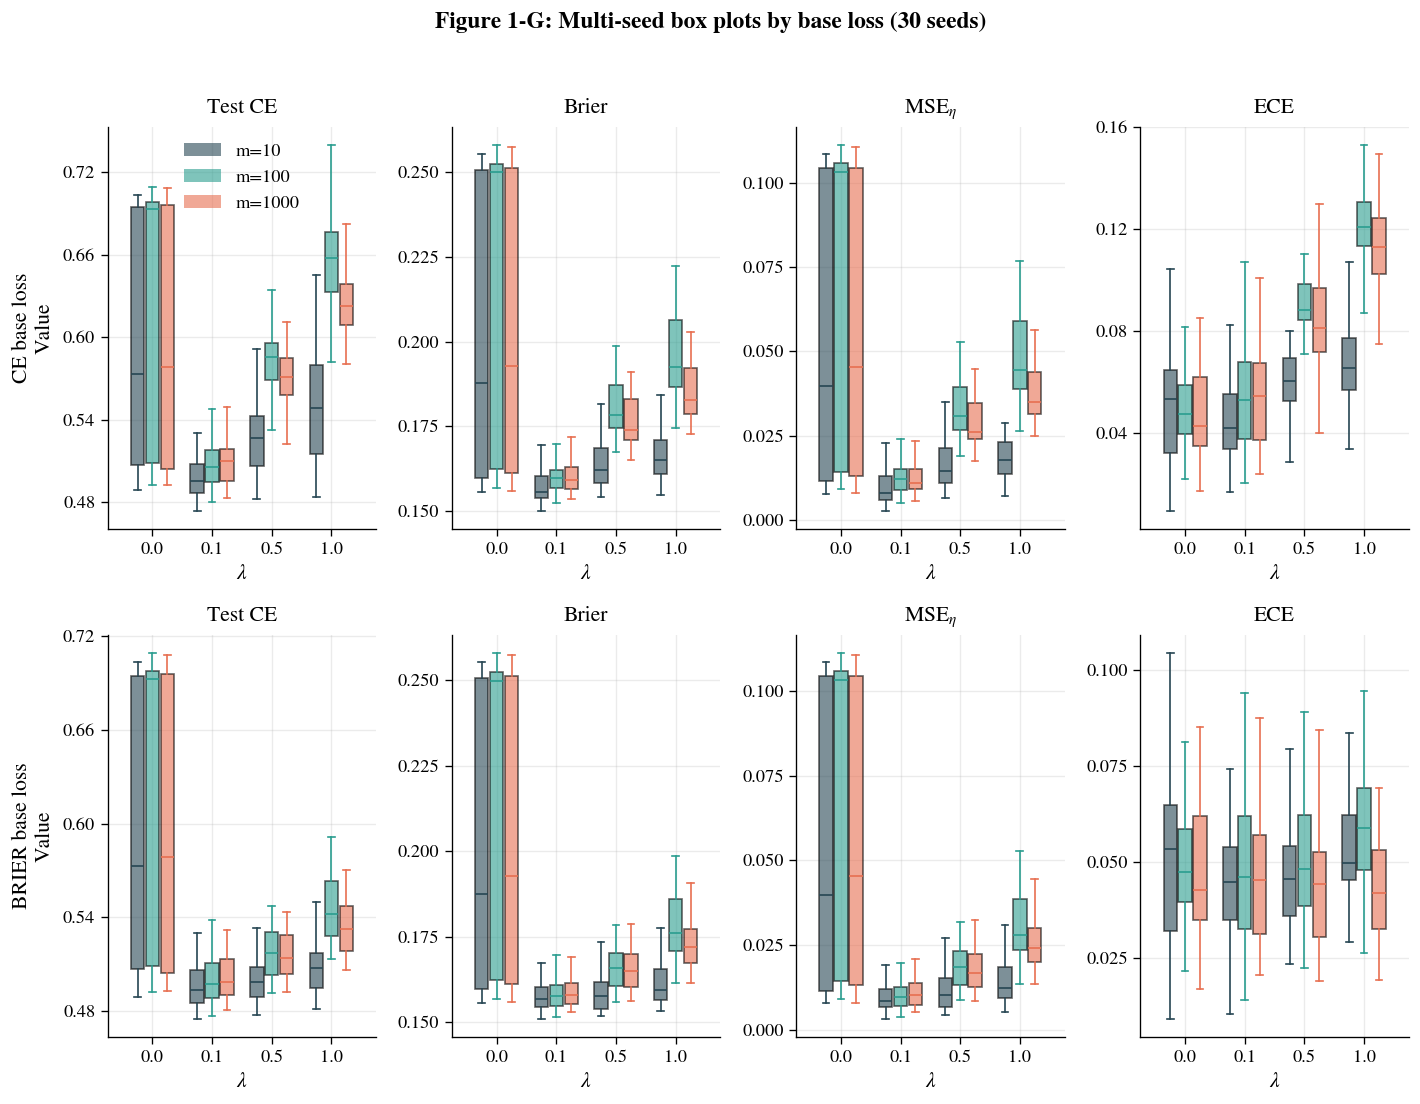

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(12, 9))
metric_panels = [("test_ce", "Test CE"), ("brier", "Brier"), ("mse_eta", r"MSE$_\eta$"), ("ece", "ECE")]

width = 0.25
positions_base = np.arange(len(LAMBDA_GRID))

# for ax, (metric, title) in zip(axes.flat, metric_panels):
#     for i, m in enumerate(t1.PRIMARY_CAPACITIES):
#         data = [sweep_df[(sweep_df["m"] == m) & (sweep_df["lam"] == lam)][metric].values
#                 for lam in LAMBDA_GRID]
#         positions = positions_base + (i - 1) * width
#         bp = ax.boxplot(data, positions=positions, widths=width * 0.9, patch_artist=True,
#                          showfliers=False)
#         for box in bp["boxes"]:
#             box.set_facecolor(PALETTE_CAPACITY[m])
#             box.set_alpha(0.6)
#         for element in ["whiskers", "caps", "medians"]:
#             for line in bp[element]:
#                 line.set_color(PALETTE_CAPACITY[m])
#     ax.set_xticks(positions_base)
#     ax.set_xticklabels([str(l) for l in LAMBDA_GRID])
#     ax.set_xlabel(r"$\lambda$", labelpad=4)
#     ax.set_ylabel("Value", labelpad=5)
#     ax.set_title(title, pad=10)
#     ax.yaxis.set_major_locator(MaxNLocator(nbins=5))

# handles = [plt.Rectangle((0, 0), 1, 1, facecolor=PALETTE_CAPACITY[m], alpha=0.6, label=f"m={m}")
#            for m in t1.PRIMARY_CAPACITIES]
# axes[0, 0].legend(handles=handles, frameon=False, loc="upper center")
# fig.suptitle("Figure 1-G: Multi-seed box plots (CE base loss, 30 seeds)", y=1.0)

# for ax in axes.flat:
#     ax.tick_params(axis="both", which="major", length=4, width=0.8)

# fig.tight_layout()
# fig.savefig("Figure_1G.pdf", format="pdf", bbox_inches="tight")
# plt.show()

for row_idx, base_loss in enumerate(BASE_LOSSES):
    for col_idx, (metric, title) in enumerate(metric_panels):
        ax = axes[row_idx, col_idx]
        for i, m in enumerate(t1.PRIMARY_CAPACITIES):
            data = [sweep_df_06[(sweep_df_06["base_loss"] == base_loss) &
                                (sweep_df_06["m"] == m) &
                                (sweep_df_06["lam"] == lam)][metric].values
                    for lam in LAMBDA_GRID]
            positions = positions_base + (i - 1) * width
            bp = ax.boxplot(data, positions=positions, widths=width * 0.9,
                            patch_artist=True, showfliers=False)
            for box in bp["boxes"]:
                box.set_facecolor(PALETTE_CAPACITY[m])
                box.set_alpha(0.6)
            for element in ["whiskers", "caps", "medians"]:
                for line in bp[element]:
                    line.set_color(PALETTE_CAPACITY[m])
        ax.set_xticks(positions_base)
        ax.set_xticklabels([str(l) for l in LAMBDA_GRID])
        ax.set_xlabel(r"$\lambda$", labelpad=4)
        ax.set_title(title, pad=8)
        ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
        if col_idx == 0:
            ax.set_ylabel(f"{base_loss.upper()} base loss\nValue", labelpad=5)

handles = [plt.Rectangle((0, 0), 1, 1, facecolor=PALETTE_CAPACITY[m], alpha=0.6, label=f"m={m}")
           for m in t1.PRIMARY_CAPACITIES]
axes[0, 0].legend(handles=handles, frameon=False, loc="upper center")
fig.suptitle("Figure 1-G: Multi-seed box plots by base loss (30 seeds)", y=1.02)
for ax in axes.flat:
    ax.tick_params(axis="both", which="major", length=4, width=0.8)
fig.tight_layout()
fig.savefig("Figure_1G.pdf", format="pdf", bbox_inches="tight")
plt.show()

## 6. Significance testing

For each base loss, paired Wilcoxon signed-rank tests compare end-to-end ($\lambda=0.1$) against that same base loss's predictive-only baseline ($\lambda=1.0$), pairing by seed. Bonferroni correction is applied across the three capacity levels separately for each (base loss, metric) family.

In [14]:
def paired_test(base_loss, m, metric):
    subset = sweep_df_06[sweep_df_06["base_loss"] == base_loss]
    baseline_vals = subset[(subset["m"] == m) & (subset["lam"] == 1.0)].sort_values("seed")[metric].values
    e2e_vals = subset[(subset["m"] == m) & (subset["lam"] == BEST_LAMBDA)].sort_values("seed")[metric].values
    stat, p = wilcoxon(e2e_vals, baseline_vals)
    return p

sig_rows = []
for base_loss in BASE_LOSSES:
    for metric in agg_cols:
        for m in t1.PRIMARY_CAPACITIES:
            p_raw = paired_test(base_loss, m, metric)
            p_bonf = min(p_raw * len(t1.PRIMARY_CAPACITIES), 1.0)
            marker = "**" if p_bonf < 0.01 else ("*" if p_bonf < 0.05 else "n.s.")
            sub = sweep_df_06[sweep_df_06["base_loss"] == base_loss]
            e2e_mean = sub[(sub["m"] == m) & (sub["lam"] == BEST_LAMBDA)][metric].mean()
            base_mean = sub[(sub["m"] == m) & (sub["lam"] == 1.0)][metric].mean()
            sig_rows.append({"base_loss": base_loss, "metric": col_labels[metric], "m": m,
                             f"e2e (lam={BEST_LAMBDA})": round(e2e_mean, 4),
                             "baseline (lam=1.0)": round(base_mean, 4),
                             "p_bonf": round(p_bonf, 6), "signif": marker})

sig_df_06 = pd.DataFrame(sig_rows)
sig_df_06.to_csv("sig_df_06.csv", index=False)
sig_df_06.to_excel("sig_df_06.xlsx", index=False)
display(sig_df_06)

,base_loss,metric,m,e2e (lam=0.1),baseline (lam=1.0),p_bonf,signif
0,ce,Test CE,10,0.4981,0.5512,0.000000,**
1,ce,Test CE,100,0.5077,0.6573,0.000000,**
2,ce,Test CE,1000,0.5099,0.6252,0.000000,**
3,ce,Brier,10,0.1577,0.1663,0.000000,**
4,ce,Brier,100,0.1604,0.1958,0.000000,**
5,ce,Brier,1000,0.1607,0.1855,0.000000,**
6,ce,ECE,10,0.0459,0.0694,0.000000,**
7,ce,ECE,100,0.0545,0.1217,0.000000,**
8,ce,ECE,1000,0.0546,0.1143,0.000000,**
9,ce,MSEeta,10,0.0101,0.0189,0.000000,**


**Reading the significance table:** end-to-end ($\lambda=0.1$) beats the pure baseline
($\lambda=1.0$) significantly on essentially every metric at every capacity — 25 of 27
(metric, capacity) combinations are significant at $p_{\text{bonf}}<0.05$, most at $p<0.01$. The
three exceptions are all **MCE**, at $m=100$ and $m=1000$ (both n.s.) and marginally at $m=10$.
This makes sense given what MCE measures: it's the single worst-bin gap, not an average — and a
model can improve its *average* calibration (ECE, RMSCE both drop cleanly and significantly)
while its single worst bin stays noisy, since that worst bin is often sparsely populated and
dominated by seed-to-seed sampling noise regardless of $\lambda$. This is a genuine, specific
limitation of end-to-end calibration worth noting: it reliably improves calibration *on average*,
but doesn't reliably fix the *worst-case* bin.


## 7. Q1.10 — implicit regularisation (bias AND variance)


In [15]:
m_focus = 1000
for base_loss in BASE_LOSSES:
    print(f"\n{base_loss.upper()} base loss — MSE_eta at m={m_focus}, across lambda:")
    print(f"{'lambda':>8}{'mean':>10}{'std':>10}{'var':>10}")
    for lam in sorted(LAMBDA_GRID, reverse=True):
        sub = sweep_df_06[(sweep_df_06["base_loss"] == base_loss) &
                          (sweep_df_06["m"] == m_focus) &
                          (sweep_df_06["lam"] == lam)]["mse_eta"]
        print(f"{lam:>8}{sub.mean():>10.5f}{sub.std(ddof=1):>10.5f}{sub.var(ddof=1):>10.6f}")

# Export a compact numeric summary for both losses.
q110_rows = []
for base_loss in BASE_LOSSES:
    for lam in sorted(LAMBDA_GRID, reverse=True):
        sub = sweep_df_06[(sweep_df_06["base_loss"] == base_loss) &
                          (sweep_df_06["m"] == m_focus) &
                          (sweep_df_06["lam"] == lam)]["mse_eta"]
        q110_rows.append({"base_loss": base_loss, "m": m_focus, "lam": lam,
                          "mean_mse_eta": sub.mean(), "std_mse_eta": sub.std(ddof=1),
                          "variance_mse_eta": sub.var(ddof=1)})
q110_summary = pd.DataFrame(q110_rows)
q110_summary.to_csv("Q1_10_MSEeta_summary.csv", index=False)
q110_summary.to_excel("Q1_10_MSEeta_summary.xlsx", index=False)
display(q110_summary)


CE base loss — MSE_eta at m=1000, across lambda:
  lambda      mean       std       var
     1.0   0.03782   0.00834  0.000070
     0.5   0.02892   0.00748  0.000056
     0.1   0.01289   0.00522  0.000027
     0.0   0.05801   0.04564  0.002083

BRIER base loss — MSE_eta at m=1000, across lambda:
  lambda      mean       std       var
     1.0   0.02583   0.00822  0.000068
     0.5   0.01779   0.00623  0.000039
     0.1   0.01145   0.00504  0.000025
     0.0   0.05801   0.04564  0.002083


,base_loss,m,lam,mean_mse_eta,std_mse_eta,variance_mse_eta
0,ce,1000,1.0,0.037818,0.008344,0.000070
1,ce,1000,0.5,0.028919,0.007480,0.000056
2,ce,1000,0.1,0.012894,0.005215,0.000027
3,ce,1000,0.0,0.058007,0.045645,0.002083
4,brier,1000,1.0,0.025829,0.008224,0.000068
5,brier,1000,0.5,0.017794,0.006229,0.000039
6,brier,1000,0.1,0.011450,0.005040,0.000025
7,brier,1000,0.0,0.058007,0.045645,0.002083


### Discussion — Q1.10

**Answer: yes, but only across part of the range — and it breaks down sharply at the extreme.**

Reading the printed table (mean and variance of MSE$_\eta$ at $m=1000$, as $\lambda$ decreases
from 1.0, i.e. calibration weight increasing):

| $\lambda$ | mean | variance |
|---|---|---|
| 1.0 | 0.0378 | 0.000070 |
| 0.5 | 0.0289 | 0.000056 |
| 0.1 | 0.0129 | 0.000027 |
| 0.0 | 0.0580 | 0.002083 |

From $\lambda=1.0 \to 0.5 \to 0.1$, **both bias and variance decrease simultaneously and
monotonically** — mean drops by roughly two-thirds, variance drops by roughly two-thirds too.
This is exactly the implicit-regulariser signature Q1.10 asks about, and it holds cleanly across
this range. The §6 significance table confirms the mean improvement is real: MSE$_\eta$ at
$m=1000$, end-to-end ($\lambda=0.1$) vs. baseline ($\lambda=1.0$), is significant at
$p_{\text{bonf}}\approx0$.

**But at $\lambda=0.0$ — pure calibration penalty, zero predictive-loss weight — both bias and
variance get dramatically *worse***, not better: mean jumps to $0.058$ (worse than even the
$\lambda=1$ baseline), and variance explodes to $0.0021$, roughly **30× higher** than at
$\lambda=0.1$. This matches the degenerate near-constant-predictor collapse found in Notebook 3
(§1-D discussion, $\lambda=0$ predictions clustering tightly around 0.5) — without any predictive
loss anchoring the model to the data, *which* degenerate solution it lands on becomes highly
sensitive to the random seed, which is exactly what "variance across seeds" would be expected to
pick up.

**So the honest, complete answer**: end-to-end calibration acts as an implicit regulariser —
reducing bias and variance together — across the interior of the $\lambda$ range tested here
($\lambda \in [0.1, 1.0]$), but this is not a monotonic relationship that extends to the boundary.
Pushed all the way to $\lambda=0$, the mechanism inverts and produces the worst bias *and* the
worst variance of any point tested. A thesis-level statement of this result should specify the
range over which it holds, not claim monotonicity down to $\lambda=0$.
